# CodeOrbit Tech — Data Science Internship
## Task 1: Data Cleaning & Exploration with Pandas

**Goal:** Load a CSV, handle missing values, duplicates and wrong data types, show basic statistics, and summarise the cleaning steps.

**Dataset:** `employee_data.csv` (60 employees + a few duplicate rows, deliberately messy).

## Step 1: Import libraries

In [ ]:
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None)

## Step 2: Load the dataset

In [ ]:
df = pd.read_csv('/content/employee_data.csv')
df.head(10)

,employee_id,name,age,city,department,salary,join_date,performance_score
0,101,Employee_1,50,Mumbai,IT,"$82,662",2018-01-01,3.9
1,102,Employee_2,36,Bangalore,Finance,"$62,970",2018-01-24,3.8
2,103,Employee_3,29,Chennai,HR,"$74,215",2018-02-16,3.1
3,104,Employee_4,42,bangalore,HR,"$83,370",2018-03-11,2.7
4,105,Employee_5,NaN,Chennai,Marketing,"$42,688",2018-04-03,4.7
5,106,Employee_6,44,Hyderabad,NaN,"$55,342",2018-04-26,4.8
6,107,Employee_7,32,Bangalore,NaN,"$67,157",2018-05-19,4.1
7,108,Employee_8,NaN,Hyderabad,Finance,"$32,327",2018-06-11,3.3
8,109,Employee_9,45,Hyderabad,Finance,"$70,772",2018-07-04,3.4
9,110,Employee_10,45,Bangalore,Finance,"$82,083",2018-07-27,4.3


## Step 3: Understand the raw data
Check shape, column types and a quick summary before changing anything.

In [ ]:
print('Rows, Columns:', df.shape)
df.info()

Rows, Columns: (63, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 63 entries, 0 to 62
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   employee_id        63 non-null     int64  
 1   name               63 non-null     object 
 2   age                58 non-null     object 
 3   city               60 non-null     object 
 4   department         59 non-null     object 
 5   salary             62 non-null     object 
 6   join_date          63 non-null     object 
 7   performance_score  58 non-null     float64
dtypes: float64(1), int64(1), object(6)
memory usage: 4.1+ KB


In [ ]:
df.describe(include='all')

,employee_id,name,age,city,department,salary,join_date,performance_score
count,63.000000,63,58,60,59,62,63,58.000000
unique,NaN,60,28,8,5,59,60,NaN
top,NaN,Employee_6,23,Bangalore,Sales,"$55,342",2018-04-26,NaN
freq,NaN,2,5,14,17,2,2,NaN
mean,129.761905,NaN,NaN,NaN,NaN,NaN,NaN,3.781034
std,17.453823,NaN,NaN,NaN,NaN,NaN,NaN,0.738528
min,101.000000,NaN,NaN,NaN,NaN,NaN,NaN,2.500000
25%,114.500000,NaN,NaN,NaN,NaN,NaN,NaN,3.100000
50%,129.000000,NaN,NaN,NaN,NaN,NaN,NaN,3.900000
75%,144.500000,NaN,NaN,NaN,NaN,NaN,NaN,4.300000


## Step 4: Detect the problems
We look for missing values, duplicates, and wrong data types.

In [ ]:
print('Missing values per column:')
print(df.isnull().sum())
print('\nDuplicate rows:', df.duplicated().sum())

Missing values per column:
employee_id          0
name                 0
age                  5
city                 3
department           4
salary               1
join_date            0
performance_score    5
dtype: int64

Duplicate rows: 3


In [ ]:
# Columns that should be numeric/date but are stored as text (object)
print(df.dtypes)
print('\nUnique values in age that are not numbers:')
print(df.loc[pd.to_numeric(df['age'], errors='coerce').isnull() & df['age'].notnull(), 'age'].unique())
print('\nCity values (note spelling/case issues):')
print(df['city'].value_counts(dropna=False))

employee_id            int64
name                  object
age                   object
city                  object
department            object
salary                object
join_date             object
performance_score    float64
dtype: object

Unique values in age that are not numbers:
['thirty']

City values (note spelling/case issues):
city
Bangalore       14
Hyderabad       14
Chennai         11
Delhi           11
Mumbai           7
NaN              3
  bangalore      1
MUMBAI           1
delhi            1
Name: count, dtype: int64


## Step 5: Clean the data
We work on a copy so the original stays untouched.

In [ ]:
clean = df.copy()
log = []  # keeps a record of every cleaning step for the report

### 5.1 Remove duplicate rows

In [ ]:
before = len(clean)
clean = clean.drop_duplicates().reset_index(drop=True)
log.append(f'Removed {before - len(clean)} duplicate rows')
print(log[-1])

Removed 3 duplicate rows


### 5.2 Fix incorrect data types
- `age`: contains text like 'N/A' and 'thirty' → convert to numbers (bad values become NaN)
- `salary`: contains `$` and commas → strip and convert to number
- `join_date`: text → real datetime
- `performance_score`: convert to float

In [ ]:
clean['age'] = pd.to_numeric(clean['age'], errors='coerce')

clean['salary'] = (clean['salary'].astype(str)
                   .str.replace(r'[\$, ]', '', regex=True)
                   .replace('nan', np.nan))
clean['salary'] = pd.to_numeric(clean['salary'], errors='coerce')

clean['join_date'] = pd.to_datetime(clean['join_date'])
clean['performance_score'] = pd.to_numeric(clean['performance_score'], errors='coerce')

log.append('Converted age, salary, performance_score to numeric and join_date to datetime')
clean.dtypes

,0
employee_id,int64
name,object
age,float64
city,object
department,object
salary,float64
join_date,datetime64[ns]
performance_score,float64


### 5.3 Standardise text columns
Remove extra spaces and make capitalisation consistent (`  bangalore ` / `MUMBAI` → `Bangalore` / `Mumbai`).

In [ ]:
for col in ['city', 'department']:
    clean[col] = clean[col].str.strip().str.title()

log.append('Stripped whitespace and standardised capitalisation in city and department')
clean['city'].value_counts(dropna=False)

,count
city,
Bangalore,14
Hyderabad,13
Delhi,12
Chennai,10
Mumbai,8
NaN,3


### 5.4 Handle missing values
Strategy:
- **Numeric columns** (`age`, `salary`, `performance_score`) → fill with the **median** (robust to outliers)
- **Categorical columns** (`city`, `department`) → fill with the **mode** (most frequent value)

In [ ]:
num_cols = ['age', 'salary', 'performance_score']
cat_cols = ['city', 'department']

for col in num_cols:
    med = clean[col].median()
    clean[col] = clean[col].fillna(med)
    log.append(f'Filled missing {col} with median ({med:.1f})')

for col in cat_cols:
    mode = clean[col].mode()[0]
    clean[col] = clean[col].fillna(mode)
    log.append(f'Filled missing {col} with mode ({mode})')

clean['age'] = clean['age'].astype(int)
print(clean.isnull().sum())

employee_id          0
name                 0
age                  0
city                 0
department           0
salary               0
join_date            0
performance_score    0
dtype: int64


## Step 6: Verify the cleaned data

In [ ]:
clean.info()
print('Duplicates left:', clean.duplicated().sum())
clean.head(10)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   employee_id        60 non-null     int64         
 1   name               60 non-null     object        
 2   age                60 non-null     int64         
 3   city               60 non-null     object        
 4   department         60 non-null     object        
 5   salary             60 non-null     float64       
 6   join_date          60 non-null     datetime64[ns]
 7   performance_score  60 non-null     float64       
dtypes: datetime64[ns](1), float64(2), int64(2), object(3)
memory usage: 3.9+ KB
Duplicates left: 0


,employee_id,name,age,city,department,salary,join_date,performance_score
0,101,Employee_1,50,Mumbai,It,82662.0,2018-01-01,3.9
1,102,Employee_2,36,Bangalore,Finance,62970.0,2018-01-24,3.8
2,103,Employee_3,29,Chennai,Hr,74215.0,2018-02-16,3.1
3,104,Employee_4,42,Bangalore,Hr,83370.0,2018-03-11,2.7
4,105,Employee_5,37,Chennai,Marketing,42688.0,2018-04-03,4.7
5,106,Employee_6,44,Hyderabad,Sales,55342.0,2018-04-26,4.8
6,107,Employee_7,32,Bangalore,Sales,67157.0,2018-05-19,4.1
7,108,Employee_8,37,Hyderabad,Finance,32327.0,2018-06-11,3.3
8,109,Employee_9,45,Hyderabad,Finance,70772.0,2018-07-04,3.4
9,110,Employee_10,45,Bangalore,Finance,82083.0,2018-07-27,4.3


## Step 7: Basic statistics
Mean, median and value counts as required by the task.

In [ ]:
stats = clean[num_cols].agg(['mean', 'median', 'min', 'max', 'std']).round(2)
stats

,age,salary,performance_score
mean,37.3,58261.93,3.76
median,37.0,56370.00,3.90
min,23.0,30197.00,2.50
max,54.0,86250.00,4.90
std,8.4,16106.81,0.71


In [ ]:
print('Mean salary  :', round(clean['salary'].mean(), 2))
print('Median salary:', clean['salary'].median())
print('Mean age     :', round(clean['age'].mean(), 2))
print('Median age   :', clean['age'].median())

Mean salary  : 58261.93
Median salary: 56370.0
Mean age     : 37.3
Median age   : 37.0


In [ ]:
print('--- City counts ---')
print(clean['city'].value_counts())
print('\n--- Department counts ---')
print(clean['department'].value_counts())

--- City counts ---
city
Bangalore    17
Hyderabad    13
Delhi        12
Chennai      10
Mumbai        8
Name: count, dtype: int64

--- Department counts ---
department
Sales        20
Finance      15
Hr           10
It            9
Marketing     6
Name: count, dtype: int64


In [ ]:
# Bonus: average salary by department
clean.groupby('department')['salary'].mean().round(0).sort_values(ascending=False)

,salary
department,
Marketing,71642.0
Finance,60644.0
It,59258.0
Hr,59044.0
Sales,51622.0


## Step 8: Save the cleaned dataset

In [ ]:
clean.to_csv('employee_data_cleaned.csv', index=False)
print('Saved: employee_data_cleaned.csv')

Saved: employee_data_cleaned.csv


## Step 9: Cleaning summary report

In [ ]:
print('CLEANING STEPS APPLIED')
print('=' * 50)
for i, step in enumerate(log, 1):
    print(f'{i}. {step}')
print(f'\nRows: {len(df)} -> {len(clean)}')

CLEANING STEPS APPLIED
1. Removed 3 duplicate rows
2. Converted age, salary, performance_score to numeric and join_date to datetime
3. Stripped whitespace and standardised capitalisation in city and department
4. Filled missing age with median (37.5)
5. Filled missing salary with median (56370.0)
6. Filled missing performance_score with median (3.9)
7. Filled missing city with mode (Bangalore)
8. Filled missing department with mode (Sales)

Rows: 63 -> 60


### Short Report
**Dataset:** Employee data (63 raw rows, 8 columns).

**Issues found:** 3 duplicate rows; missing values in age, city, department, salary and performance_score; wrong data types (age, salary and performance_score stored as text, join_date as string); inconsistent city names (extra spaces, mixed case); invalid entries in age ('N/A', 'thirty').

**Actions taken:** removed duplicates, converted columns to correct types, standardised text, filled numeric gaps with the median and categorical gaps with the mode.

**Result:** a clean dataset of 60 rows with no missing values and no duplicates, saved as `employee_data_cleaned.csv`.

**Key learning:** always inspect data first (`info`, `isnull`, `duplicated`), clean on a copy, and document each step.

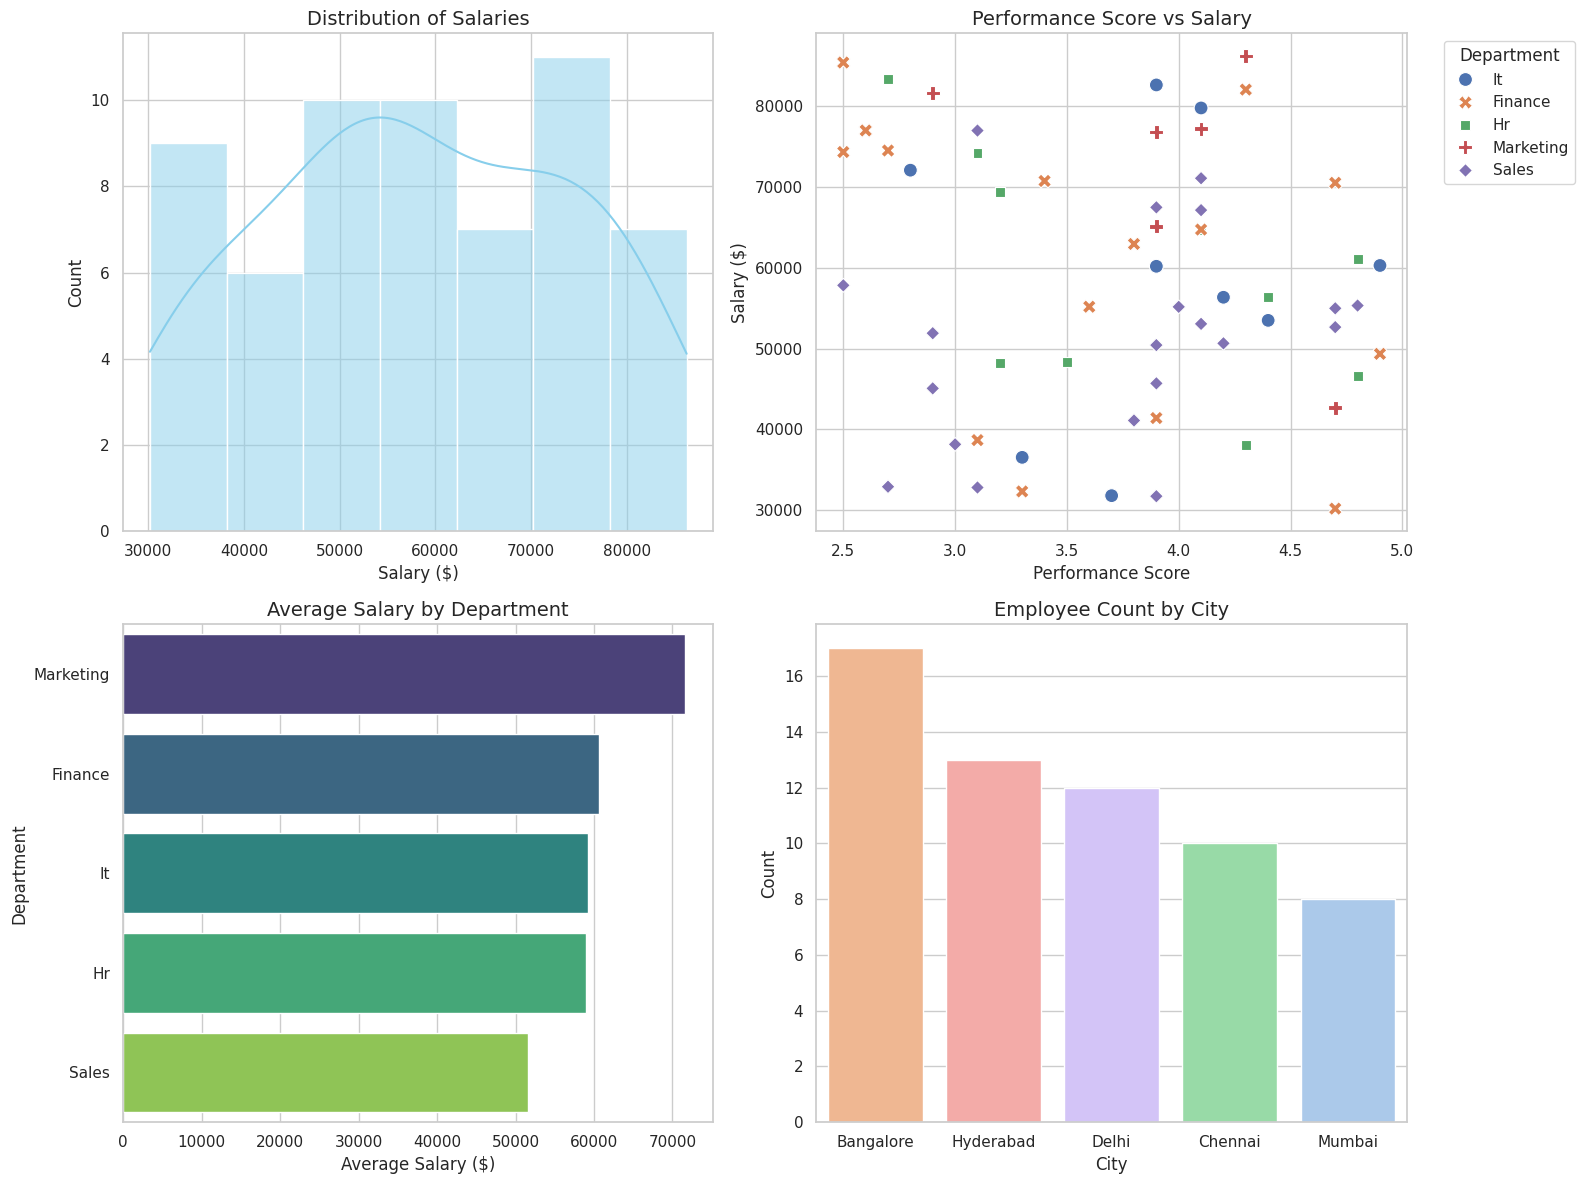

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for the plots
sns.set_theme(style="whitegrid")

# Create a multi-plot figure
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Salary Distribution
sns.histplot(data=clean, x='salary', kde=True, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Distribution of Salaries', fontsize=14)
axes[0, 0].set_xlabel('Salary ($)')
axes[0, 0].set_ylabel('Count')

# 2. Performance Score vs Salary (Scatter Plot colored by Department)
sns.scatterplot(data=clean, x='performance_score', y='salary', hue='department', style='department', s=100, ax=axes[0, 1])
axes[0, 1].set_title('Performance Score vs Salary', fontsize=14)
axes[0, 1].set_xlabel('Performance Score')
axes[0, 1].set_ylabel('Salary ($)')
axes[0, 1].legend(title='Department', bbox_to_anchor=(1.05, 1), loc='upper left')

# 3. Average Salary by Department
dept_salary = clean.groupby('department')['salary'].mean().reset_index().sort_values(by='salary', ascending=False)
sns.barplot(data=dept_salary, x='salary', y='department', ax=axes[1, 0], palette='viridis', hue='department', legend=False)
axes[1, 0].set_title('Average Salary by Department', fontsize=14)
axes[1, 0].set_xlabel('Average Salary ($)')
axes[1, 0].set_ylabel('Department')

# 4. Employee Counts by City
sns.countplot(data=clean, x='city', ax=axes[1, 1], palette='pastel', order=clean['city'].value_counts().index, hue='city', legend=False)
axes[1, 1].set_title('Employee Count by City', fontsize=14)
axes[1, 1].set_xlabel('City')
axes[1, 1].set_ylabel('Count')

plt.tight_layout()
plt.show()

```markdown
## Step 10: Key Performance Indicators (KPIs)

We calculate and display important organizational metrics from our clean dataset to provide a high-level summary dashboard.
```

In [ ]:
# 1. High-level Summary Metrics (KPIs)
total_headcount = len(clean)
total_salary_bill = clean['salary'].sum()
avg_salary = clean['salary'].mean()
avg_performance = clean['performance_score'].mean()

print("==================================================")
print("              ORGANIZATIONAL KPIs                 ")
print("==================================================")
print(f"Total Headcount        : {total_headcount} employees")
print(f"Total Salary Budget    : ${total_salary_bill:,.2f}")
print(f"Average Annual Salary  : ${avg_salary:,.2f}")
print(f"Average Performance    : {avg_performance:.2f} / 5.0")
print("==================================================")

# 2. Top Performing Department KPI
dept_perf = clean.groupby('department')['performance_score'].mean().sort_values(ascending=False)
print("\nAverage Performance by Department:")
for dept, score in dept_perf.items():
    print(f"- {dept:<12}: {score:.2f} / 5.0")

              ORGANIZATIONAL KPIs                 
Total Headcount        : 60 employees
Total Salary Budget    : $3,495,716.00
Average Annual Salary  : $58,261.93
Average Performance    : 3.76 / 5.0

Average Performance by Department:
- Marketing   : 3.97 / 5.0
- It          : 3.91 / 5.0
- Hr          : 3.81 / 5.0
- Sales       : 3.71 / 5.0
- Finance     : 3.61 / 5.0
